In [ ]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Añadir el directorio raíz del proyecto al sys.path para importar módulos desde src
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# Importar el módulo dataset propio de la carpeta src
import src.dataset as dataset

print("Módulo cargado correctamente.")

Módulo cargado correctamente.


In [8]:
manifest_path = PROJECT_ROOT / "data" / "manifest.csv"

if manifest_path.exists():
    df_manifest = pd.read_csv(manifest_path)
    print("Manifiesto cargado desde disco (data/manifest.csv).")
else:
    df_manifest = dataset.build_manifest()
    print("Manifiesto generado desde las imágenes.")

print(f"Total de imágenes encontradas en el dataset: {len(df_manifest)}")
df_manifest.head(5)

Manifiesto cargado desde disco (data/manifest.csv).
Total de imágenes encontradas en el dataset: 5856


,filepath,filename,label_name,label,patient_id
0,C:\Users\Ruben Caicedo\Desktop\Mater_en_IA_y_C...,IM-0115-0001.jpeg,NORMAL,0,IM-0115-0001
1,C:\Users\Ruben Caicedo\Desktop\Mater_en_IA_y_C...,IM-0117-0001.jpeg,NORMAL,0,IM-0117-0001
2,C:\Users\Ruben Caicedo\Desktop\Mater_en_IA_y_C...,IM-0119-0001.jpeg,NORMAL,0,IM-0119-0001
3,C:\Users\Ruben Caicedo\Desktop\Mater_en_IA_y_C...,IM-0122-0001.jpeg,NORMAL,0,IM-0122-0001
4,C:\Users\Ruben Caicedo\Desktop\Mater_en_IA_y_C...,IM-0125-0001.jpeg,NORMAL,0,IM-0125-0001


C:\Users\Ruben Caicedo\AppData\Local\Temp\ipykernel_14876\2371326519.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_manifest, x='label_name', palette='Set2')


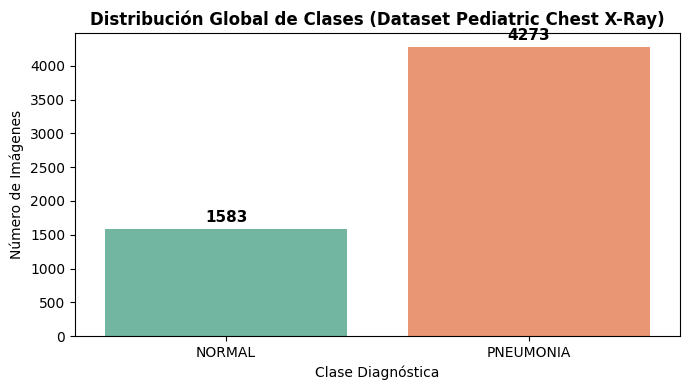

In [4]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df_manifest, x='label_name', palette='Set2')
plt.title("Distribución Global de Clases (Dataset Pediatric Chest X-Ray)", fontsize=12, fontweight='bold')
plt.xlabel("Clase Diagnóstica")
plt.ylabel("Número de Imágenes")

# Añadir etiquetas cuantitativas sobre las barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 3), 
                textcoords='offset points')

plt.tight_layout()
plt.show()

In [5]:
split_path = PROJECT_ROOT / "data" / "manifest_split.csv"

if split_path.exists():
    df_split = pd.read_csv(split_path)
    print("Split cargado exitosamente desde data/manifest_split.csv")
else:
    df_split = dataset.build_manifest()

print("\n=== DISTRIBUCIÓN DE MUESTRAS POR SPLIT (70/15/15) ===")
print(df_split['split'].value_counts())

# COMPROBACIÓN ESTRICTA DE PATIENT LEAKAGE
train_patients = set(df_split[df_split['split'] == 'train']['patient_id'])
val_patients = set(df_split[df_split['split'] == 'val']['patient_id'])
test_patients = set(df_split[df_split['split'] == 'test']['patient_id'])

leak_train_val = train_patients.intersection(val_patients)
leak_train_test = train_patients.intersection(test_patients)
leak_val_test = val_patients.intersection(test_patients)

print("\n=== VERIFICACIÓN DE PATIENT LEAKAGE ===")
print(f"Pacientes compartidos entre Train y Val:  {len(leak_train_val)}")
print(f"Pacientes compartidos entre Train y Test: {len(leak_train_test)}")
print(f"Pacientes compartidos entre Val y Test:   {len(leak_val_test)}")

if len(leak_train_val) == 0 and len(leak_train_test) == 0 and len(leak_val_test) == 0:
    print("\n✅ ¡ÉXITO! No existe fuga de datos (Patient Leakage). Los pacientes son 100% independientes entre los conjuntos.")
else:
    print("\n⚠️ ALERTA: Se detectaron pacientes compartidos entre subconjuntos.")

Split cargado exitosamente desde data/manifest_split.csv

=== DISTRIBUCIÓN DE MUESTRAS POR SPLIT (70/15/15) ===
split
train    1406
val       302
test      292
Name: count, dtype: int64

=== VERIFICACIÓN DE PATIENT LEAKAGE ===
Pacientes compartidos entre Train y Val:  0
Pacientes compartidos entre Train y Test: 0
Pacientes compartidos entre Val y Test:   0

✅ ¡ÉXITO! No existe fuga de datos (Patient Leakage). Los pacientes son 100% independientes entre los conjuntos.
